In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error

In [2]:
PROJECT_ROOT = Path.cwd().parent

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "train_cleaned.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 11)


,record_id,date,students_on_campus,menu_price_rs,temp_c,exam_days_left,special_dishes,queue_minutes_yesterday,day_type,block,plates_sold
0,R00001,2026-01-01,2120,54,17.0,16,5,24.6,holiday,Hostel,459
1,R00002,2026-01-01,4167,120,38.6,58,3,27.5,weekday,Hostel,258
2,R00003,2026-01-01,4301,116,43.4,24,3,6.1,saturday,Hostel,263
3,R00004,2026-01-01,4446,31,32.2,0,5,33.8,weekday,A-Block,416
4,R00005,2026-01-01,2257,73,18.1,24,1,34.5,holiday,B-Block,404


In [3]:
TARGET = "plates_sold"

DROP_COLUMNS = ["record_id", "date", TARGET]

X = df.drop(columns=DROP_COLUMNS)
y = df[TARGET]

print("Features:", X.columns.tolist())
print("Target shape:", y.shape)

Features: ['students_on_campus', 'menu_price_rs', 'temp_c', 'exam_days_left', 'special_dishes', 'queue_minutes_yesterday', 'day_type', 'block']
Target shape: (1000,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (800, 8)
Test size: (200, 8)


In [5]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['students_on_campus', 'menu_price_rs', 'temp_c', 'exam_days_left', 'special_dishes', 'queue_minutes_yesterday']
Categorical features: ['day_type', 'block']


In [6]:
experiments = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [7]:
results = []
trained_models = {}

for name, model in experiments.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 3)
    })

    trained_models[name] = pipeline

    print(f"{name}: MAE = {mae:.3f}")

Linear Regression: MAE = 13.714
Random Forest: MAE = 21.991
Gradient Boosting: MAE = 16.103


In [8]:
results_df = pd.DataFrame(results).sort_values("MAE")

results_df

,Model,MAE
0,Linear Regression,13.714
2,Gradient Boosting,16.103
1,Random Forest,21.991


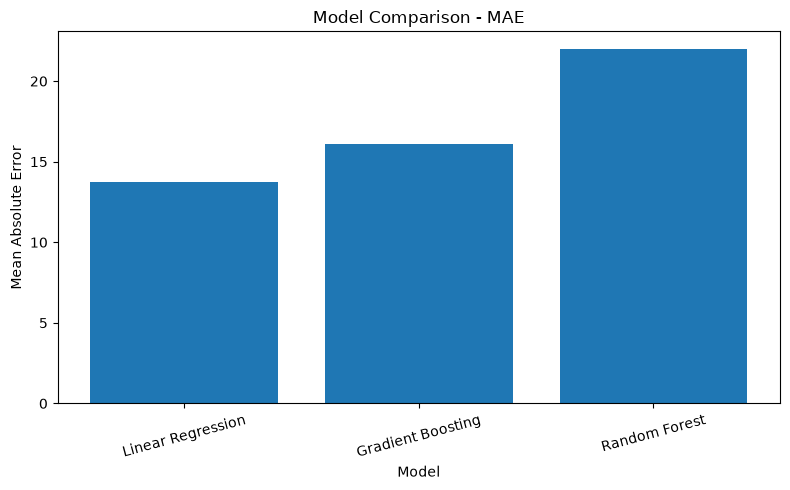

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["MAE"])
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")
plt.title("Model Comparison - MAE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_mae = results_df.iloc[0]["MAE"]

print("Best Model:", best_model_name)
print("Best MAE:", best_mae)

Best Model: Linear Regression
Best MAE: 13.714


In [11]:
results_df.to_csv(
    PROJECT_ROOT / "reports" / "model_comparison.csv",
    index=False
)

print("Experiment results saved.")

Experiment results saved.
